# Program 19: the gradient-projection variant

**What:** replace the penalty with a hard constraint that removes forbidden directions from the gradients.

**How:** following the GPM paper (Saha et al., 2021), project each layer's gradient so its update cannot push features into U_c. Start with the last layer only, then extend to more layers.

**Why:** a penalty can be outweighed by a strong task loss; a projection cannot. Comparing the two is a natural ablation.

**Understanding note:** a soft penalty trades forgetting against learning through λ. A hard projection guarantees the constraint but may block too much learning.

**Done when:** you have a table comparing programs 18 and 19 on all metrics.

## Where this fits (for a first-time reader)

Program 18's guard is a **penalty**: an extra loss term. The network can still move the features into the forbidden directions if the task loss gains more than the penalty costs (λ sets the price).

The **projection** variant forbids it instead. During backpropagation, the gradient arrives at the features h(x) as a 512-dim vector g, which says "move h this way to lower the loss". We remove its part inside the forbidden directions:

$$g \;\leftarrow\; g - Q\,Q^\top g$$

where Q is an orthonormal basis of all forgotten items' signatures together. So no loss, not the new task's and not DER++'s replay, can **directly** push the features along those directions.

**What we implement, and what we don't.** GPM (Saha et al., 2021) projects the *weight* gradients of every layer, so that no layer's update changes its outputs inside a protected subspace. That needs a basis per layer, built from that layer's inputs. Here we start, as the roadmap suggests, at the last stage: the projection acts on the gradient **at the feature layer** (the output of the body), which is exactly where the signatures live. It blocks every *direct* push along U_c. The weights of the body still change for other reasons, and those changes can move features into U_c *indirectly*. Extending it to per-layer GPM is a natural next step if this variant turns out promising.

Same two experiments as program 18: Part A on the stream, Part B on wolf + the similar task. The tables include program 17 and program 18 (best λ) next to the projection.

## 1. Setup

**Time:** Part A about 15 minutes, Part B about 8 minutes.

In [1]:
import gc, json, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.derpp, common.badteacher, common.features, common.metrics, common.stream, common.clu
for module in (common.utils, common.data, common.models, common.derpp, common.badteacher, common.features, common.metrics, common.stream, common.clu):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np

from common.clu import load_result, make_config, run_or_load
from common.data import SplitCIFAR100
from common.metrics import all_metrics, item_view
from common.utils import RESULTS_DIR, log_run

# Program 14's retrain model: probe accuracy on each task when the task was NEVER learned (the target).
RETRAIN_PROBE = None
for line in (RESULTS_DIR / "runs.jsonl").read_text().splitlines():
    entry = json.loads(line)
    if entry["program"] == "14_feature_probe":
        RETRAIN_PROBE = np.array(entry["results"]["probe"]["retrain"])

def metrics_row(res, kind="til"):
    s = res["summary"][kind]
    return s["RA"], s["FA"], s["Spill"], s["Relapse"]


def show_table(runs, retrain_probe=None):
    """runs: name -> result dict. Prints the four metrics and the probe numbers on forgotten items."""
    print(f"{'run':>28} | {'RA':>6} {'FA':>6} {'Spill':>6} {'Relapse':>7} | {'RA cil':>6} {'FA cil':>6} | "
          f"{'probe: before':>13} {'after U':>8} {'end':>6} {'peak rise':>9}")
    for name, res in runs.items():
        ra, fa, sp, rel = metrics_row(res, "til")
        rac, fac, _, _ = metrics_row(res, "cil")
        p = res["summary"].get("probe")
        ptxt = (f"{p['before']*100:12.1f}% {p['after_U']*100:7.1f}% {p['end']*100:5.1f}% {p['peak_rise']*100:+8.1f}"
                if p else f"{'-':>13} {'-':>8} {'-':>6} {'-':>9}")
        print(f"{name:>28} | {ra*100:5.1f}% {fa*100:5.1f}% {sp*100:6.1f} {rel*100:7.1f} | {rac*100:5.1f}% {fac*100:5.1f}% | {ptxt}")
    if retrain_probe is not None:
        print(f"\nretrain model (program 14), probe on the same forgotten tasks: {retrain_probe*100:.1f}%  (the target)")
    print("RA/FA/Spill/Relapse: task-IL (chance 10%); 'cil' = class-IL. Probe: 10-way on each forgotten task's features.")


def plot_forgotten(runs, title, file, show_retrain=True):
    """Head task-IL accuracy and feature probe of the forgotten items after every request."""
    import warnings
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
    for name, res in runs.items():
        acc, learned, forgotten, rows = item_view(res, "til")
        head = [np.nanmean(acc[r, forgotten[r]]) * 100 if forgotten[r].any() else np.nan for r in range(len(acc))]
        line, = axes[0].plot(head, marker="o", ms=3, label=name)
        if "probe" in res:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                axes[1].plot(np.nanmean(res["probe"], axis=1) * 100, marker="o", ms=3, color=line.get_color(), label=name)
    labels = [str(s) for s in next(iter(runs.values()))["requests"]]
    for ax in axes:
        ax.set_xticks(range(len(labels)), labels, rotation=45, fontsize=8)
    axes[0].axhline(10, color="gray", ls="--", lw=1, label="chance")
    axes[0].set(title="Head: task-IL accuracy of forgotten tasks (average, %)", ylabel="accuracy (%)", ylim=(0, 100))
    axes[1].set(title="Features: probe accuracy of forgotten tasks (average, %)", ylabel="probe accuracy (%)")
    if show_retrain and RETRAIN_PROBE is not None:
        axes[1].axhline(RETRAIN_PROBE[[int(s[1:]) for s in labels if s[0] == "U"]].mean() * 100,
                        color="green", ls=":", lw=1.5, label="retrain (target)")
    for ax in axes:
        ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / file, dpi=120)
    plt.show()

WOLF_TASKS = {
    "A": ["wolf", "camel", "cattle", "chimpanzee", "elephant", "kangaroo", "bus", "bicycle", "orchid", "apple"],
    "similar": ["bear", "leopard", "lion", "tiger", "fox", "porcupine", "possum", "raccoon", "skunk", "otter"],
}


def run_wolf(prefix, seeds, data, **overrides):
    """L task A -> U wolf (with the simple fixes) -> L the similar task, once per seed."""
    lab = {n: data.class_names.index(n) for n in data.class_names}
    tasks = {0: [lab[n] for n in WOLF_TASKS["A"]], 1: [lab[n] for n in WOLF_TASKS["similar"]]}
    out = {}
    for seed in seeds:
        cfg = make_config(name=f"{prefix}_s{seed}", seed=seed, head_reset=True, mask_forgotten_logits=True, **overrides)
        print(f"--- {cfg['name']}")
        out[seed] = run_or_load(cfg, data, requests=[("L", 0), ("U", lab["wolf"]), ("L", 1)], tasks=tasks, level="class")
    return out


def wolf_numbers(res):
    """Probe of wolf (wolf vs the other task-A classes, chance 50%) before U / after U / at the end, and the
    task-IL accuracy of all kept classes at the end."""
    b, a, e = list(res["summary"]["probe"]["per_item"].values())[0]
    kept = res["learned"][-1] & ~res["forgotten"][-1]
    return {"before": b, "after_U": a, "end": e, "rise": e - a, "kept_acc": float(np.nanmean(res["acc_til"][-1][kept]))}


def show_wolf(groups):
    """groups: name -> {seed: result}. Mean ± spread over seeds."""
    print(f"{'config':>26} | {'probe before U':>14} {'after U':>12} {'end':>12} {'rise':>12} | {'kept acc (end)':>14}")
    table = {}
    for name, per_seed in groups.items():
        nums = [wolf_numbers(r) for r in per_seed.values()]
        table[name] = {k: (np.mean([n[k] for n in nums]), np.std([n[k] for n in nums])) for k in nums[0]}
        t = table[name]
        print(f"{name:>26} | " + " ".join(f"{t[k][0]*100:6.1f} ± {t[k][1]*100:3.1f}" if k != "rise" else
                                         f"{t[k][0]*100:+6.1f} ± {t[k][1]*100:3.1f}"
                                         for k in ("before", "after_U", "end", "rise")) +
              f" | {t['kept_acc'][0]*100:7.1f} ± {t['kept_acc'][1]*100:3.1f}")
    print("probe: wolf vs the other 9 task-A classes on test features (chance 50%; a never-trained network gets ~72%)")
    return table

SEEDS = [0, 1, 2]
CFG = make_config(name="19_projection", stream="task15_seed0", head_reset=True, mask_forgotten_logits=True,
                  guard="projection", signature="specific")
SETTINGS = {"config": CFG, "seeds": SEEDS}

## 2. Part A: projection on the stream

In [2]:
data = SplitCIFAR100(seed=0, batch_size=32, num_workers=2)
result = run_or_load(CFG, data)

[  0] L5   kept  66.0%  train acc 64.7%  (78s)


[  1] L2   kept  73.8%  train acc 78.5%  (154s)


[  2] L3   kept  72.4%  train acc 74.5%  (231s)


[  3] L4   kept  76.1%  train acc 81.5%  (307s)


[  4] U5   kept  77.4%  forgot head  11.2%  probe  72.7%  forget imgs 5000 (494 in buffer), deleted 494  (335s)


[  5] L9   kept  77.5%  forgot head   8.9%  probe  72.5%  train acc 85.8%  (415s)


... (5 outputs left out)

[ 11] L7   kept  78.6%  forgot head  10.9%  probe  76.8%  train acc 93.0%  (740s)


[ 12] L6   kept  79.4%  forgot head  12.5%  probe  76.6%  train acc 88.9%  (819s)


[ 13] L1   kept  80.0%  forgot head   9.7%  probe  76.3%  train acc 92.6%  (900s)


[ 14] U4   kept  76.9%  forgot head  10.0%  probe  75.3%  forget imgs 5000 (199 in buffer), deleted 199  (928s)


## 3. Part B: wolf and the similar task

In [3]:
wolf_proj = run_wolf("19_wolf_projection", SEEDS, data, guard="projection", signature="specific")
del data
gc.collect()

--- 19_wolf_projection_s0


[  0] L0   kept  63.2%  train acc 64.7%  (77s)


[  1] U73  kept  64.0%  forgot head   0.0%  probe  86.0%  forget imgs 500 (203 in buffer), deleted 203  (104s)


[  2] L1   kept  61.4%  forgot head   0.0%  probe  85.5%  train acc 59.9%  (183s)


--- 19_wolf_projection_s1


[  0] L0   kept  64.6%  train acc 65.2%  (76s)


... (3 outputs left out)

[  0] L0   kept  65.0%  train acc 64.3%  (76s)


[  1] U73  kept  65.9%  forgot head   0.0%  probe  90.5%  forget imgs 500 (198 in buffer), deleted 198  (104s)


[  2] L1   kept  63.6%  forgot head   0.0%  probe  84.0%  train acc 62.0%  (183s)


0

## 4. Programs 17, 18 and 19 side by side

Part A: all metrics on the stream. Program 18 is shown for every λ that was run. Part B: wolf's probe and the kept classes' accuracy.

                         run |     RA     FA  Spill Relapse | RA cil FA cil | probe: before  after U    end peak rise
             17_simple_fixes |  76.9%  11.7%    7.9     2.7 |  54.0%   0.0% |         79.0%    77.5%  76.1%     +1.4
               18_guard_l0.1 |  76.3%  10.2%    9.4     2.3 |  55.3%   0.0% |         78.9%    78.1%  76.8%     +1.2
                 18_guard_l1 |  77.5%   9.9%    7.7     1.4 |  56.8%   0.0% |         78.5%    77.0%  75.4%     +1.2
                18_guard_l10 |  76.2%  12.0%    9.5     5.2 |  54.4%   0.0% |         78.9%    78.6%  76.2%     +0.6
               19_projection |  76.9%  10.0%    9.1     2.1 |  55.3%   0.0% |         78.4%    77.2%  75.3%     +0.6

retrain model (program 14), probe on the same forgotten tasks: 71.1%  (the target)
RA/FA/Spill/Relapse: task-IL (chance 10%); 'cil' = class-IL. Probe: 10-way on each forgotten task's features.


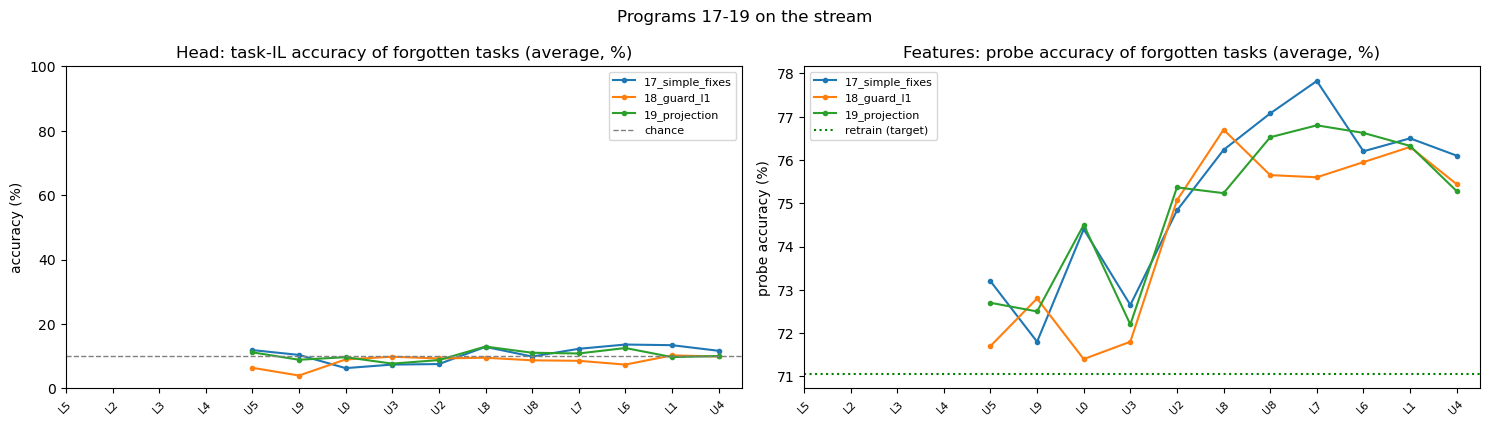

In [4]:
runs = {}
for name in ["17_simple_fixes", "18_guard_l0.1", "18_guard_l1", "18_guard_l10"]:
    r = load_result(name)
    if r is not None:
        runs[name] = r
runs["19_projection"] = result
forgotten_tasks = [int(s[1:]) for s in result["requests"] if str(s)[0] == "U"]
show_table(runs, RETRAIN_PROBE[forgotten_tasks].mean() if RETRAIN_PROBE is not None else None)
plot_forgotten({k: v for k, v in runs.items() if k in ("17_simple_fixes", "18_guard_l1", "19_projection")},
               "Programs 17-19 on the stream", "19_compare_stream.png")

In [5]:
groups = {}
for name, prefix in [("simple fixes (no guard)", "18_wolf_fixes"), ("penalty, specific (18)", "18_wolf_specific")]:
    per_seed = {s: load_result(f"{prefix}_s{s}") for s in SEEDS}
    if all(v is not None for v in per_seed.values()):
        groups[name] = per_seed
groups["projection, specific (19)"] = wolf_proj
wolf_table = show_wolf(groups)

                    config | probe before U      after U          end         rise | kept acc (end)
   simple fixes (no guard) |   88.8 ± 1.6   90.0 ± 1.8   88.0 ± 0.7   -2.0 ± 1.1 |    63.9 ± 0.6
    penalty, specific (18) |   86.8 ± 0.2   89.3 ± 2.2   86.5 ± 2.5   -2.8 ± 1.5 |    63.4 ± 0.8
 projection, specific (19) |   86.8 ± 0.5   88.3 ± 1.8   84.5 ± 0.7   -3.8 ± 2.5 |    63.5 ± 1.7
probe: wolf vs the other 9 task-A classes on test features (chance 50%; a never-trained network gets ~72%)


## 5. Log the run

In [6]:
log_run("19_guard_gradproj", SETTINGS,
        {"stream": result["summary"],
         "wolf": {name: {k: [round(v[0], 4), round(v[1], 4)] for k, v in t.items()} for name, t in wolf_table.items()}})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Did the projection lower the forgotten tasks' probe more or less than the penalty (program 18)?
2. Did it block too much learning? Compare RA and the kept accuracy in Part B.
3. The projection only blocks *direct* pushes at the feature layer. Did features still move into the forbidden directions indirectly? (Look at the probe's rise in Part B.)
4. Soft (penalty) or hard (projection): which would you keep for the final method, and why?